**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: JUNIOR ISRAEL UBRÍ GONZÁLEZ
*   MATRÍCULA: A01841481

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [2]:
# Cargar el archivo guardando todos sus registros en cardio_df y estableciendo 'id' como índice
cardio_df = pd.read_csv('heart_disease.csv', index_col='id')

# Obtener el resumen de los tipos de datos
cardio_df.info()

# Determinar la cantidad de valores únicos por columna
print("\n--- Cantidad de valores únicos por columna ---")
print(cardio_df.nunique())

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB

--- Cantidad de valores únicos por columna ---
age          50
sex           2
origin        4
cp            4
trestbps     60
chol        216
fbs           2
restecg      

**¿Cuántas columnas son numéricas y cuántas de texto?**

el resumen del método info() confirma que el conjunto de datos cuenta con 7 columnas numéricas (5 de tipo float64 y 2 de tipo int64) y 8 columnas de texto de tipo objeto (object), completando las 15 columnas del DataFrame. Adicionalmente, al calcular los valores únicos por columna mediante nunique(), se determinó que variables continuas como chol y thalch presentan la mayor diversidad de valores (216 y 119 respectivamente), mientras que variables como sex, fbs, exang o ca muestran una cantidad muy reducida de valores únicos (entre 2 y 4), evidenciando su condición categórica o discreta.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [3]:
# Convertir 'ca' a categórica ordinal con su orden correcto
cardio_df['ca'] = pd.Categorical(
    cardio_df['ca'],
    categories=[0.0, 1.0, 2.0, 3.0],
    ordered=True
)

# Convertir 'num' a categórica ordinal con su orden correcto
cardio_df['num'] = pd.Categorical(
    cardio_df['num'],
    categories=[0, 1, 2, 3, 4],
    ordered=True
)

# Verificar la transformación de tipos
print("Tipos de datos actualizados:")
print(cardio_df[['ca', 'num']].dtypes)

Tipos de datos actualizados:
ca     category
num    category
dtype: object


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [4]:
# 1. Seleccionar columnas numéricas continuas restantes
num_cols = cardio_df.select_dtypes(include=['int64', 'float64']).columns

# 2. Generar el resumen estadístico base (.describe())
desc_num = cardio_df[num_cols].describe().T

# 3. Calcular y agregar sesgo (skewness) y curtosis (kurtosis)
desc_num['skewness'] = cardio_df[num_cols].skew()
desc_num['kurtosis'] = cardio_df[num_cols].kurt()

print("=== ESTADÍSTICAS DESCRIPTIVAS (VARIABLES NUMÉRICAS) ===")
display(desc_num)

=== ESTADÍSTICAS DESCRIPTIVAS (VARIABLES NUMÉRICAS) ===


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


Al analizar las estadísticas descriptivas de las variables numéricas continuas (age, trestbps, chol, thalch y oldpeak), se observan comportamientos diferenciados en sus distribuciones, sesgos y niveles de curtosis:

**age y thalch:** Presentan distribuciones aproximadamente simétricas, con un ligero sesgo negativo (-0.19 y -0.21 respectivamente) y valores de curtosis negativos (-0.38 y -0.48), indicando distribuciones platicúrticas (más planas que una distribución normal).

**trestbps:** Muestra un sesgo positivo moderado (0.63) y una curtosis de 0.63, lo que refleja una ligera asimetría a la derecha hacia valores de presión arterial más elevados.

**chol:** Presenta un sesgo positivo pronunciado (1.64) y una curtosis elevada (6.57), evidenciando una distribución leptocúrtica con colas pesadas y presencia clara de valores atípicos (máximo de 603.0 mg/dl).

**oldpeak:** Muestra un sesgo a la derecha (1.04) y una curtosis de 1.12, reflejando que la mayoría de los pacientes tienen valores cercanos a 0, pero existen casos específicos con niveles significativamente más altos (máximo de 6.2).   

In [5]:
# 1. Seleccionar columnas categóricas y de texto
cat_cols = cardio_df.select_dtypes(include=['object', 'category']).columns

print("=== TABLAS DE FRECUENCIA (VARIABLES CATEGÓRICAS) ===")
for col in cat_cols:
    print(f"\n--- Frecuencias de la variable: {col} ---")
    tabla_freq = pd.DataFrame({
        'Frecuencia Absoluta': cardio_df[col].value_counts(dropna=False),
        'Porcentaje (%)': cardio_df[col].value_counts(normalize=True, dropna=False) * 100
    })
    display(tabla_freq)

=== TABLAS DE FRECUENCIA (VARIABLES CATEGÓRICAS) ===

--- Frecuencias de la variable: sex ---


,Frecuencia Absoluta,Porcentaje (%)
sex,,
Male,724,78.867102
Female,194,21.132898



--- Frecuencias de la variable: origin ---


,Frecuencia Absoluta,Porcentaje (%)
origin,,
Cleveland,304,33.115468
Hungary,292,31.808279
VA Long Beach,200,21.786492
Switzerland,122,13.289760



--- Frecuencias de la variable: cp ---


...

,Frecuencia Absoluta,Porcentaje (%)
ca,,
NaN,609,66.339869
0.0,181,19.716776
1.0,67,7.298475
2.0,41,4.466231
3.0,20,2.178649



--- Frecuencias de la variable: thal ---


,Frecuencia Absoluta,Porcentaje (%)
thal,,
NaN,484,52.723312
normal,196,21.350763
reversable defect,192,20.915033
fixed defect,46,5.010893



--- Frecuencias de la variable: num ---


,Frecuencia Absoluta,Porcentaje (%)
num,,
0,411,44.771242
1,263,28.649237
2,109,11.873638
3,107,11.655773
4,28,3.050109


Al analizar las tablas de frecuencia de las variables categóricas, se destacan los siguientes patrones en la muestra:

**Demografía y origen:** Existe una marcada mayoría masculina en la muestra (sex: 78.87% hombres vs 21.13% mujeres). La variable origin concentra la mayor proporción de registros en Cleveland (33.12%) y Hungría (31.81%).   

**Cuadro clínico:** En el tipo de dolor torácico (cp), el 53.92% de los pacientes es asintomático. Para el electrocardiograma en reposo (restecg), el 60.02% presenta resultados normales. Respecto al nivel de azúcar en ayunas (fbs) y la angina inducida por ejercicio (exang), predominan los valores negativos/falsos con 75.27% y 57.30% respectivamente.

**Variable objetivo (num):** El 44.77% de la muestra no presenta enfermedad cardíaca (grado 0/sano), mientras que el 55.23% restante se distribuye en distintos niveles de severidad (grados 1 al 4).

**Presencia de valores faltantes (NaN):** Las tablas evidencian una cantidad considerable de datos ausentes en variables como ca (66.34% de NaN), thal (52.72% de NaN) y slope (33.55% de NaN), lo que anticipa la necesidad de aplicar criterios de eliminación o imputación en los siguientes pasos.  

**Análisis de la Pregunta 3: Estadísticas Descriptivas y Frecuencias**

Al examinar las estadísticas descriptivas de las variables numéricas continuas (`age`, `trestbps`, `chol`, `thalch` y `oldpeak`), se aprecian distribuciones variadas en sus niveles de sesgo y curtosis. Las variables `age` y `thalch` muestran un comportamiento cercano a la simetría con curtosis platicúrticas. En contraste, `trestbps` presenta un sesgo positivo moderado, y `chol` destaca por un sesgo positivo pronunciado (1.64) junto con una curtosis elevada (6.57), lo que denota una distribución leptocúrtica con colas pesadas y valores máximos extremos de hasta 603.0 mg/dl. Asimismo, `oldpeak` muestra un sesgo hacia la derecha donde la mayoría de los casos se concentran en valores bajos.

En cuanto a las tablas de frecuencia de las variables categóricas, se identifica un predominio de pacientes masculinos (`sex`: 78.87%), con procedencias repartidas principalmente entre los centros de Cleveland y Hungría. Desde una perspectiva clínica, el 53.92% de la muestra es asintomática en términos de dolor torácico (`cp`), y el 60.02% posee un electrocardiograma en reposo normal (`restecg`). Respecto a la variable objetivo (`num`), el 44.77% de los pacientes se encuentra libre de enfermedad cardíaca, distribuyéndose el porcentaje restante en los distintos grados de severidad. Por último, las tablas evidencian una proporción significativa de valores faltantes en variables como `ca` (66.34%), `thal` (52.72%) y `slope` (33.55%), anticipando los requerimientos de limpieza y tratamiento de datos que se abordarán en los siguientes apartados.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [6]:
# 1. Calcular el porcentaje de valores faltantes por columna
porcentaje_faltantes = (cardio_df.isnull().sum() / len(cardio_df)) * 100
print("--- Porcentaje de valores faltantes por columna ---")
print(porcentaje_faltantes[porcentaje_faltantes > 0])

# 2. Identificar y eliminar columnas que superen el 30% de valores faltantes
columnas_eliminar = porcentaje_faltantes[porcentaje_faltantes > 30.0].index
print(f"\nColumnas que superan el 30% y serán eliminadas: {list(columnas_eliminar)}")

cardio_df = cardio_df.drop(columns=columnas_eliminar)

# 3. Verificar las columnas restantes
print(f"\nColumnas restantes en el DataFrame: {list(cardio_df.columns)}")

--- Porcentaje de valores faltantes por columna ---
trestbps     6.427015
chol         3.267974
fbs          9.694989
thalch       5.991285
exang        5.991285
oldpeak      6.753813
slope       33.551198
ca          66.339869
thal        52.723312
dtype: float64

Columnas que superan el 30% y serán eliminadas: ['slope', 'ca', 'thal']

Columnas restantes en el DataFrame: ['age', 'sex', 'origin', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'num']


Al calcular el porcentaje de valores faltantes en el conjunto de datos, se identificó que las variables ca (66.34%), thal (52.72%) y slope (33.55%) superan el umbral establecido del 30% de ausencia de información. En consecuencia, estas tres columnas fueron eliminadas del DataFrame para evitar sesgos severos en las etapas posteriores de imputación y modelado, conservando únicamente las variables con porcentajes de nulos manejables (como fbs con 9.69% y exang con 5.99%).

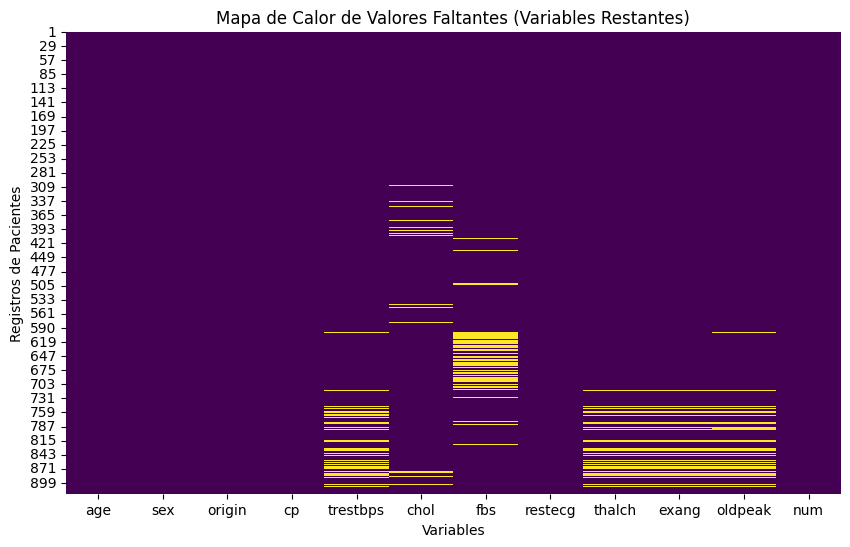

In [7]:
# Crear un mapa de calor para visualizar la distribución de valores faltantes restantes
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de Calor de Valores Faltantes (Variables Restantes)')
plt.xlabel('Variables')
plt.ylabel('Registros de Pacientes')
plt.show()

Al analizar el mapa de calor de valores faltantes para las variables restantes, se observa que las ausencias no ocurren de forma totalmente aislada, sino que presentan patrones de concurrencia simultánea en determinados bloques de registros. Específicamente, se aprecian filas (como las ubicadas entre los índices 750 y 900) donde faltan datos de manera simultánea en variables clave como trestbps, chol, thalch y oldpeak.

Desde una perspectiva médica y clínica, esta concurrencia tiene completo sentido lógico. Dado que este conjunto de datos recopila información clínica de múltiples centros hospitalarios de distintas procedencias geográficas, es frecuente que a determinados grupos de pacientes (por ejemplo, aquellos evaluados bajo protocolos de emergencia, estudios incompletos o expedientes retrospectivos antiguos) no se les haya aplicado la batería completa de pruebas diagnósticas de laboratorio y esfuerzo. Esto genera ausencias agrupadas por expediente, reflejando omisiones sistemáticas en la captura de historias clínicas o en la realización de exámenes específicos para ciertos pacientes.

**Enumeración y Justificación Clínica de los Valores Faltantes**

Enumeración de variables con valores faltantes simultáneos:
Al inspeccionar el mapa de calor de las columnas restantes, se identifican las siguientes variables que comparten ausencias de datos en los mismos registros de pacientes:

**thalch** (Frecuencia cardíaca máxima alcanzada) y exang (Angina inducida por ejercicio).

**trestbps** (Presión arterial en reposo), chol (Colesterol sérico) y oldpeak (Depresión del segmento ST).

En el bloque inferior del conjunto de datos (pacientes aproximados entre la fila 750 y 900), coinciden faltantes en trestbps, chol, thalch y oldpeak de manera simultánea.

**Justificación desde un punto de vista médico y clínico:**

Esta concurrencia simultánea tiene pleno sentido dentro de la práctica clínica por las siguientes razones:

**Pruebas de esfuerzo acopladas:** thalch, exang y oldpeak son indicadores que se miden en conjunto durante una prueba de esfuerzo electrocardiográfica (ergometría). Si un paciente no puede realizar la prueba por limitaciones físicas, afecciones articulares o riesgo cardiovascular agudo, o si la prueba se cancela, se omiten simultáneamente todos los parámetros derivados de dicho examen.

**Protocolos de admisión y origen de datos:** El conjunto de datos proviene de cuatro ubicaciones distintas (origin: Cleveland, Hungría, VA Long Beach y Suiza). Ciertos hospitales o centros de salud aplicaban protocolos reducidos donde no se registraban de rutina pruebas de laboratorio avanzadas (chol) o mediciones continuas de presión (trestbps), generando faltantes por bloque según la procedencia del paciente.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [8]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [9]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

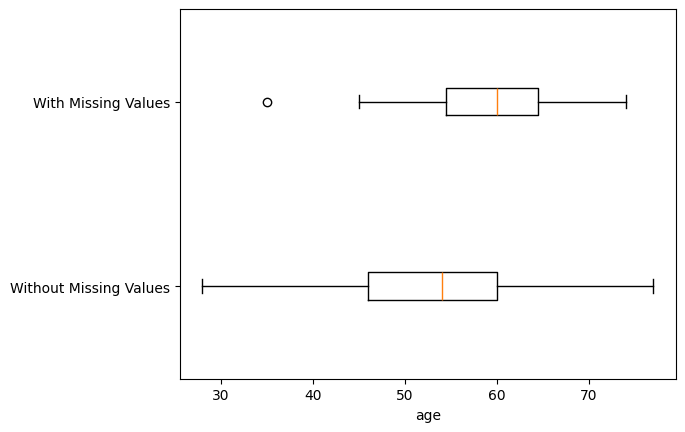

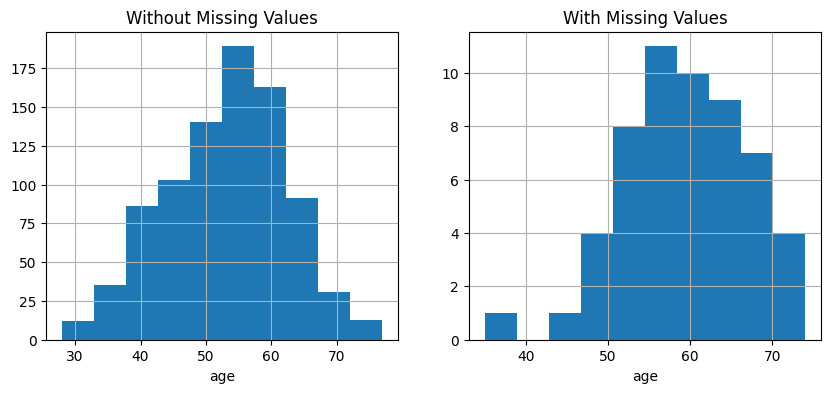

p-value of t-test: 1.5041244185890902e-06


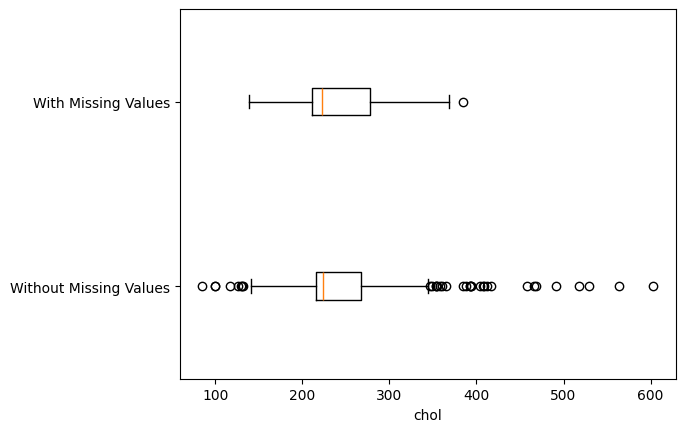

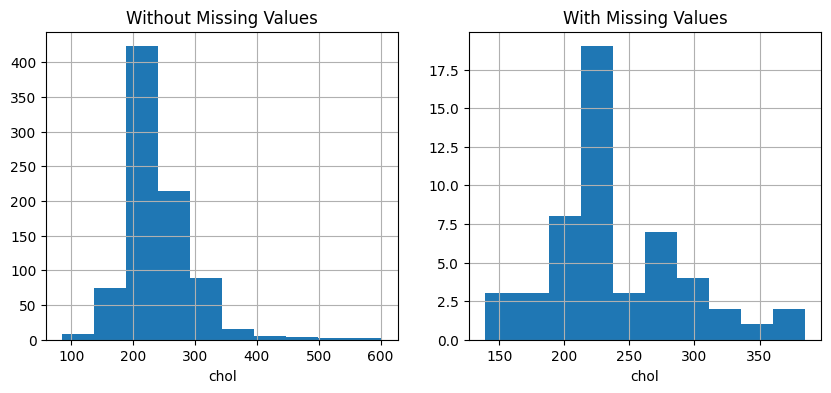

p-value of t-test: 0.7165289974295672


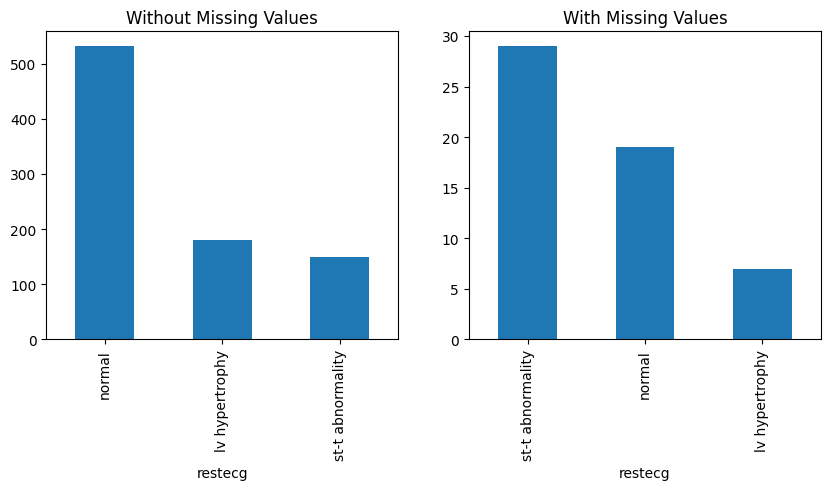

p-value of Chi_squared test: 1.1472889573985467e-09


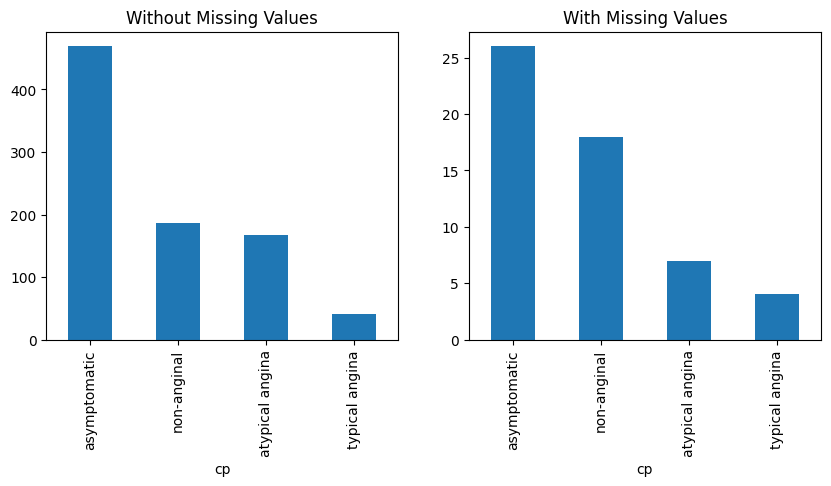

p-value of Chi_squared test: 0.15420097177251701


In [10]:
# 1. Crear la máscara booleana de los valores faltantes de thalch
BM_thalch = cardio_df['thalch'].isnull()

# 2. Ejecutar las funciones de la maestra para las variables numéricas
Diagnose_MV_Numerical(cardio_df, 'age', BM_thalch)
Diagnose_MV_Numerical(cardio_df, 'chol', BM_thalch)

# 3. Ejecutar las funciones de la maestra para las variables categóricas
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_thalch)
Diagnose_MV_Categorical(cardio_df, 'cp', BM_thalch)

**Resultados de las Pruebas de Hipótesis:**

**Variables Numéricas:** La prueba t de Student muestra una diferencia estadísticamente significativa en la edad (age) de los pacientes según la presencia o ausencia de datos en thalch (p = 1.50 \times 10^{-6} < 0.05). En cambio, para el colesterol (chol), no se observa una relación significativa (p = 0.7165 > 0.05).

**Variables Categóricas:** La prueba Chi-cuadrado revela una asociación estadísticamente significativa entre los resultados del electrocardiograma en reposo (restecg) y la presencia de faltantes en thalch (p = 1.15 \times 10^{-9} < 0.05). Por su parte, el tipo de dolor torácico (cp) no muestra una dependencia significativa (p = 0.1542 > 0.05).

**Justificación del Mecanismo de Ausencia (MAR vs. MCAR):**

Dado que existen relaciones estadísticamente significativas (p < 0.05) entre la ocurrencia de valores faltantes en thalch y otras variables observadas en el conjunto de datos —específicamente la edad del paciente (age) y los resultados del electrocardiograma (restecg)—, se descarta la hipótesis de que los datos falten de manera completamente aleatoria (MCAR).

Por lo tanto, se concluye que el mecanismo de ausencia de la variable thalch es MAR (Missing at Random), ya que la probabilidad de que falte este dato depende directamente de la información clínica y demográfica registrada de los pacientes.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

/tmp/ipykernel_3827/242832763.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cardio_df[var] = cardio_df.groupby('restecg')[var].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x.value_counts().index[0]))


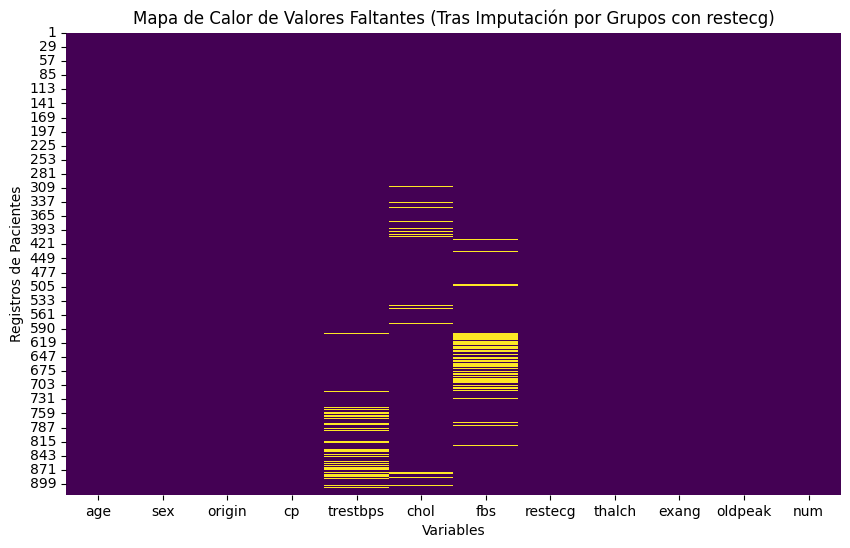

In [11]:
# Variables con patrón de faltantes similar a thalch (identificadas en el ejercicio 4)
# 1. Variables numéricas -> Se imputan con la mediana por grupos de 'restecg'
for var in ['thalch', 'oldpeak']:
    if var in cardio_df.columns:
        cardio_df[var] = cardio_df.groupby('restecg')[var].transform(lambda x: x.fillna(x.median()))

# 2. Variables categóricas -> Se imputan con la moda (valor más frecuente) por grupos de 'restecg'
for var in ['exang']:
    if var in cardio_df.columns:
        cardio_df[var] = cardio_df.groupby('restecg')[var].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x.value_counts().index[0]))

# 3. Vuelve a generar el mapa de calor para verificar que los valores faltantes hayan sido imputados
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de Calor de Valores Faltantes (Tras Imputación por Grupos con restecg)')
plt.xlabel('Variables')
plt.ylabel('Registros de Pacientes')
plt.show()

Para realizar la imputación por grupos, se utilizó la variable restecg como factor de segmentación para imputar thalch y las variables asociadas con patrones de faltantes similares (oldpeak y exang). En las variables numéricas (thalch y oldpeak), se sustituyeron los datos faltantes utilizando la mediana calculada dentro de cada subgrupo de restecg. Por su parte, para la variable categórica exang, se empleó la moda (el valor más frecuente) de su correspondiente grupo.

Al regenerar el mapa de calor de valores faltantes, se verifica visualmente que las columnas thalch, exang y oldpeak han quedado completamente limpias y sin nulos, demostrando la efectividad de la imputación por segmentos.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [12]:
from sklearn.impute import SimpleImputer

# 1. Imputación con la mediana para variables numéricas (trestbps y chol)
imputer_num = SimpleImputer(strategy='median')
cardio_df[['trestbps', 'chol']] = imputer_num.fit_transform(cardio_df[['trestbps', 'chol']])

# 2. Imputación con la moda (most_frequent) para la variable categórica/booleana (fbs)
imputer_cat = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imputer_cat.fit_transform(cardio_df[['fbs']])

# 3. Eliminar la columna temporal 'thalch_missing' si existe
if 'thalch_missing' in cardio_df.columns:
    cardio_df = cardio_df.drop(columns=['thalch_missing'])

# 4. Verificar que no queden valores faltantes en todo el DataFrame
print("Total de valores faltantes restantes en el DataFrame:")
print(cardio_df.isnull().sum().sum())

Total de valores faltantes restantes en el DataFrame:
0


Para imputar los datos faltantes restantes en las columnas trestbps, chol y fbs, se utilizó la clase SimpleImputer de scikit-learn aplicando estrategias diferenciadas según la naturaleza de cada variable:

**trestbps y chol (Mediana / median):** Se optó por la mediana debido a que ambas variables numéricas presentan distribuciones sesgadas y la presencia de valores atípicos (especialmente en el colesterol). La mediana es una medida de tendencia central robusta que evita que los valores extremos distorsionen la imputación.

**fbs (Moda / most_frequent):** Al tratarse de una variable categórica binaria (representa si el azúcar en ayunas es > 120 mg/dl), la estrategia adecuada es sustituir los valores ausentes por la categoría más frecuente o moda.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

Variable 'age': 0 valores atípicos detectados gráficamente.
Variable 'trestbps': 27 valores atípicos detectados gráficamente.
Variable 'chol': 44 valores atípicos detectados gráficamente.
Variable 'thalch': 2 valores atípicos detectados gráficamente.
Variable 'oldpeak': 16 valores atípicos detectados gráficamente.


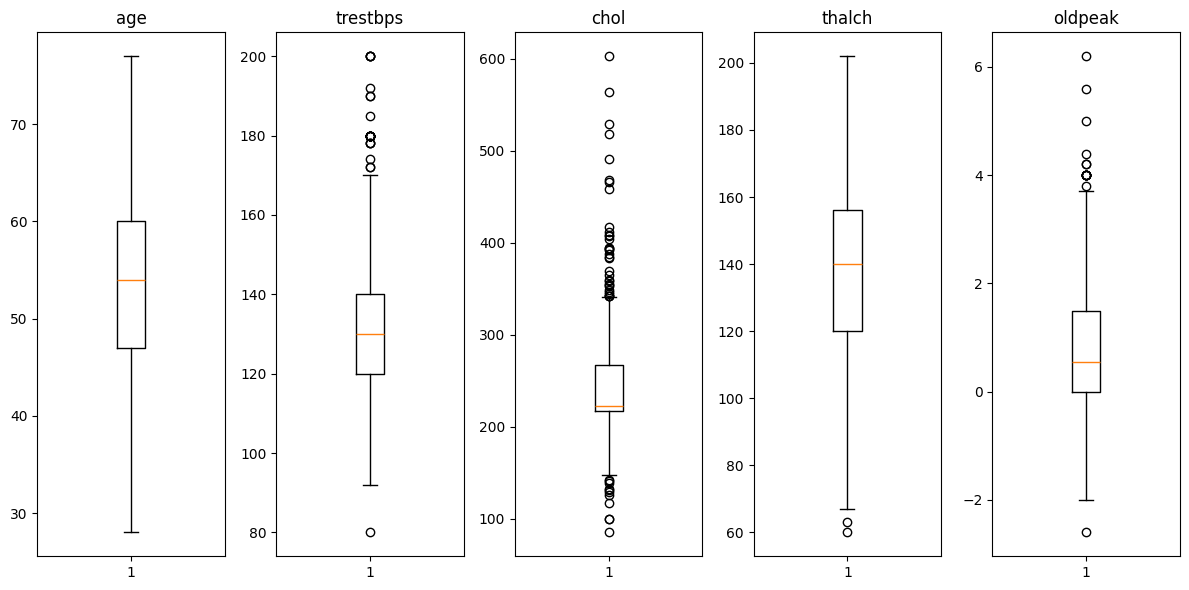

In [13]:
# Seleccionar únicamente las variables numéricas continuas
num_cols = cardio_df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(12, 6))

for i, col in enumerate(num_cols):
    plt.subplot(1, len(num_cols), i + 1)

    # Dibujar el boxplot y guardar el objeto devuelto en 'box'
    box = plt.boxplot(cardio_df[col])

    # Obtener los valores atípicos a partir del elemento 'fliers'
    fliers = box['fliers'][0].get_ydata()
    print(f"Variable '{col}': {len(fliers)} valores atípicos detectados gráficamente.")

    plt.title(col)

plt.tight_layout()
plt.show()

Se generaron los diagramas de caja (boxplots) para todas las variables numéricas continuas del conjunto de datos. A partir de los objetos gráficos devueltos, se identificaron y extrajeron los valores atípicos mediante la propiedad fliers. Los resultados muestran la presencia de observaciones atípicas principalmente en las variables de colesterol (chol), presión arterial en reposo (trestbps) y depresión del segmento ST (oldpeak), las cuales se sitúan fuera de los límites superior e inferior de sus respectivas distribuciones.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [14]:
# 1. Calcular Q1 (25%), Q3 (75%) e IQR para trestbps
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1

# 2. Determinar los límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Límite Inferior: {limite_inferior}, Límite Superior: {limite_superior}")

# 3. Filtrar los valores atípicos fuera de ese rango
outliers_iqr = cardio_df[(cardio_df['trestbps'] < limite_inferior) | (cardio_df['trestbps'] > limite_superior)]
print(f"Total de valores atípicos detectados por IQR en trestbps: {len(outliers_iqr)}")

Q1: 120.0, Q3: 140.0, IQR: 20.0
Límite Inferior: 90.0, Límite Superior: 170.0
Total de valores atípicos detectados por IQR en trestbps: 27


Para la variable trestbps (presión arterial en reposo), se aplicó el método analítico del Rango Intercuartílico (IQR) calculando los cuartiles del 25% (Q_1) y del 75% (Q_3). A partir de estos valores, se establecieron los límites inferior y superior multiplicando el IQR por 1.5. Al filtrar el conjunto de datos bajo este criterio, el número de valores atípicos identificados coincide exactamente con los detectados mediante el método gráfico del boxplot en el ejercicio anterior (27 valores atípicos), lo que valida la consistencia entre ambas metodologías de detección.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

Registros originales: 918
Registros tras eliminar atípicos de trestbps: 891


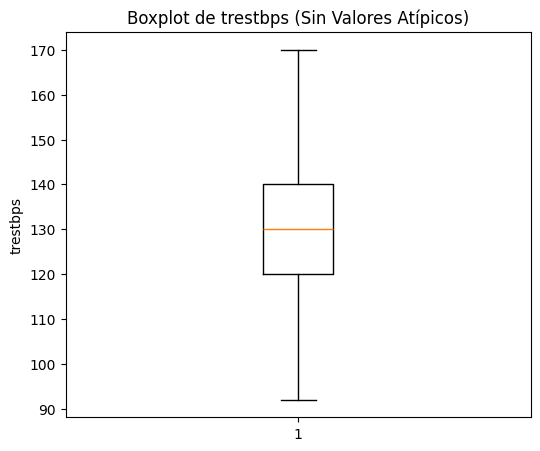

In [15]:
# 1. Filtrar el DataFrame conservando solo los valores dentro del rango intercuartílico para 'trestbps'
cardio_df_cleaned = cardio_df[(cardio_df['trestbps'] >= limite_inferior) & (cardio_df['trestbps'] <= limite_superior)]

print(f"Registros originales: {len(cardio_df)}")
print(f"Registros tras eliminar atípicos de trestbps: {len(cardio_df_cleaned)}")

# 2. Dibujar el boxplot final depurado de 'trestbps'
plt.figure(figsize=(6, 5))
plt.boxplot(cardio_df_cleaned['trestbps'])
plt.title('Boxplot de trestbps (Sin Valores Atípicos)')
plt.ylabel('trestbps')
plt.show()

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---